SPDX-FileCopyrightText: 2026-present Marta Szulca (tusiya) <szulcam2410@gmail.com>, Hubert Stankiewicz (limebel) <stankiewicz.huberto@gmail.com>

SPDX-License-Identifier: MIT

In [18]:
import pandas as pd
import csv

from model_elements import (
    load_standard_quality_model,
    load_procedure_inputs_from_csv,
    load_weights_from_csv,
    CompositeElement,
    ProcedureElement,
    WeightedAverageStrategy,
    EvaluationScenario,
)

import visualizations as viz

In [19]:
import variants.intuition as vi
base_data, options = vi.prepare_intuition() # this creates the intuition files



DOSTĘPNE KATEGORIE UŻYTKOWNIKÓW:

Wiek
──────────────────────────────────────────────────
  1 │ 18 - 24
  2 │ 45 - 54
  3 │ 25 - 34
  4 │ 35 - 44

Grupa
──────────────────────────────────────────────────
  5 │ W ramach spotkań z klientami, pracy zdalnej, itp.
  6 │ Jako student

Częstotliwość użytkowania
──────────────────────────────────────────────────
  7 │ Codziennie lub prawie codziennie

Kompetencje cyfrowe
──────────────────────────────────────────────────
  8 │ Bardzo wysoki - często pomagam innym w obsłudze programów oraz sprawnie uczę się nowych
  9 │ Wysoki - swobodnie korzystam z większości programów i zazwyczaj samodzielnie radzę sobie z nowymi lub nietypowymi zadaniami
 10 │ Średni - radzę sobie z podstawową obsługą programów, ale w przypadku trudniejszych zadań często potrzebuję pomocy


In [20]:
filtered_survey = vi.intuition(base_data, options, [1])


Respondents included: 12
Exported 33 hierarchy relationships.


In [40]:
import importlib
importlib.reload(viz)

<module 'visualizations' from '/home/marta/thesis/code/cloudquality/src/cloudquality/visualizations.py'>


Generating respondent demographics...
Selected respondents: 33

Wiek
Wiek
18 - 24    12
45 - 54    10
25 - 34     6
35 - 44     5
Name: count, dtype: int64

Grupa
Grupa
W ramach spotkań z klientami, pracy zdalnej, itp.    21
Jako student                                          5
Jako wykładowca / nauczyciel                          3
Jako uczeń                                            3
Tylko do sporadycznych spotkań                        1
Name: count, dtype: int64

Częstotliwość użytkowania
Częstotliwość użytkowania
Codziennie lub prawie codziennie     22
Raz na trzy miesiące lub rzadziej     4
Kilka (2-5) razy w miesiącu           4
Raz na miesiąc lub dwa miesiące       2
NaN                                   1
Name: count, dtype: int64

Kompetencje cyfrowe
Kompetencje cyfrowe
Bardzo wysoki - często pomagam innym w obsłudze programów oraz sprawnie uczę się nowych                                        15
Wysoki - swobodnie korzystam z większości programów i zazwyczaj samodzieln

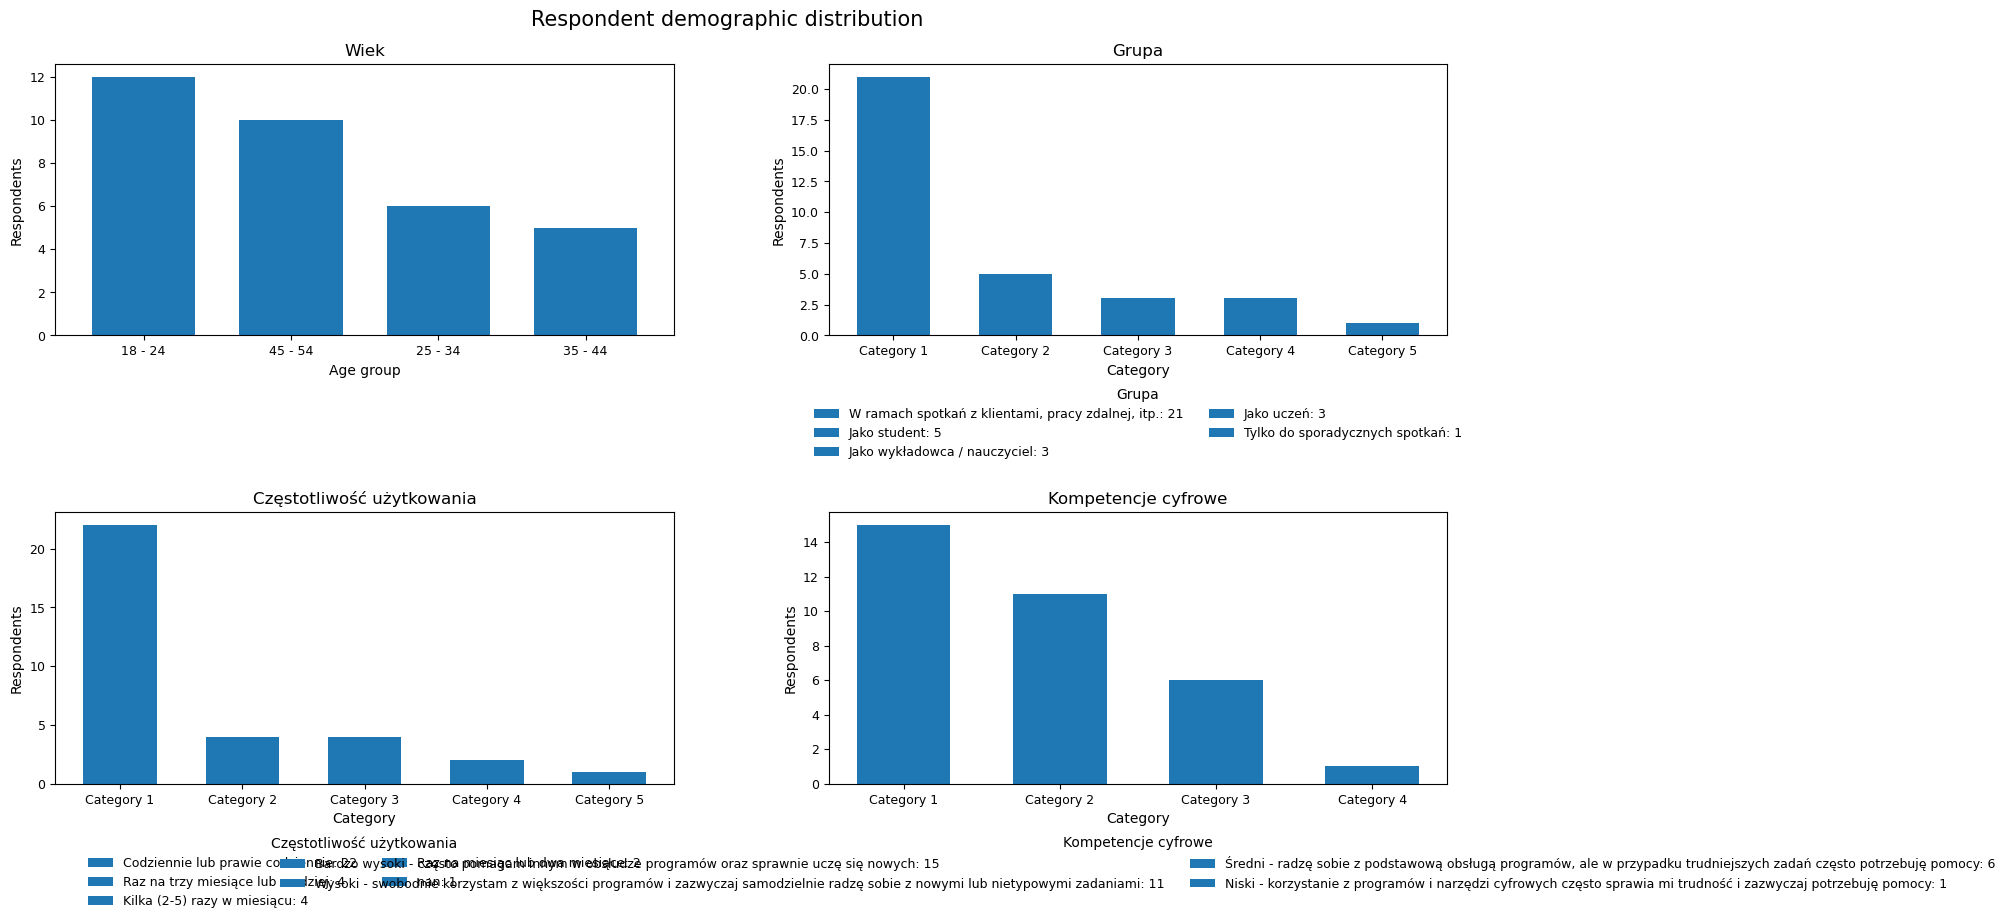

In [41]:
viz.generate_demographic_visualizations(base_data)

files

In [22]:
SYSTEM_FILE = "../../system_metrics.csv"
SURVEY_FILE = "../../user_surveys.csv"
WEIGHTS_FILE = "../../weights.csv"

OUTPUT_FILE = "../../aggregation_comparison.csv"

data loading

In [23]:
model = load_standard_quality_model()

system_inputs = load_procedure_inputs_from_csv(SYSTEM_FILE)

survey_df = pd.read_csv(SURVEY_FILE, encoding="utf-8-sig")
survey_df = survey_df.apply(pd.to_numeric, errors="coerce")

# Mean score for each procedure across respondents
survey_scores = survey_df.mean().to_dict()

ahp_weights = load_weights_from_csv(WEIGHTS_FILE)

In [24]:
def complete_weights(element, supplied_weights):
    result = {}

    if not isinstance(element, CompositeElement):
        return result

    provided = supplied_weights.get(element.name, {})

    result[element.name] = {
        child.name: float(provided.get(child.name, 1.0))
        for child in element.subelements
    }

    for child in element.subelements:
        result.update(complete_weights(child, supplied_weights))

    return result

In [25]:
complete_ahp_weights = complete_weights(model, ahp_weights)

In [26]:
weighted_average = WeightedAverageStrategy()

def calculate(element, scores, weights):
    """Recursively aggregate procedure scores."""

    if isinstance(element, ProcedureElement):
        if element.name not in scores:
            raise KeyError(f"Missing score for: {element.name}")
        return float(scores[element.name])

    child_scores = [
        calculate(child, scores, weights)
        for child in element.subelements
    ]

    child_weights = [
        weights[element.name][child.name]
        for child in element.subelements
    ]

    return weighted_average.aggregate(child_scores, child_weights)

scores

In [27]:
def transform_system_metrics(element):
    """Calculate transformed scores for all procedure nodes."""
    scores = {}

    def visit(node):
        if isinstance(node, ProcedureElement):
            if node.name not in system_inputs:
                raise KeyError(f"Missing system metric: {node.name}")

            scores[node.name] = node.default_strategy.evaluate(
                system_inputs[node.name]
            )
        else:
            for child in node.subelements:
                visit(child)

    visit(element)
    return scores

In [28]:
system_scores = transform_system_metrics(model)

Analytical model

In [29]:
equal_weights = complete_weights(model, {})

scenario_1 = calculate(
    model,
    system_scores,
    equal_weights
)

Intuitive model

In [30]:
scenario_2 = calculate(
    model,
    survey_scores,
    complete_ahp_weights
)

hybrid model

In [31]:
scenario_3 = calculate(
    model,
    system_scores,
    complete_ahp_weights
)

results

In [32]:
results = {
    "System metrics + equal weights": {},
    "User surveys + AHP weights": {},
    "System metrics + AHP weights": {}
}

scenarios = [
    ("System metrics + equal weights", system_scores, equal_weights),
    ("User surveys + AHP weights", survey_scores, complete_ahp_weights),
    ("System metrics + AHP weights", system_scores, complete_ahp_weights),
]

for label, scores, weights in scenarios:
    results[label]["Model jakości"] = calculate(model, scores, weights)

    for child in model.subelements:
        results[label][child.name] = calculate(child, scores, weights)

display

In [33]:
comparison = pd.DataFrame(results)
comparison.index.name = "Criterion"

print("\n========== AGGREGATION COMPARISON ==========\n")
print(comparison.round(3).to_string())

comparison.round(4).to_csv(
    OUTPUT_FILE,
    encoding="utf-8-sig"
)

print(f"\nResults saved to: {OUTPUT_FILE}")


========== AGGREGATION COMPARISON ==========

                System metrics + equal weights  User surveys + AHP weights  System metrics + AHP weights
Criterion                                                                                               
Model jakości                            4.268                       3.239                         3.778
Funkcjonalność                           4.820                       3.200                         4.799
Wydajność                                4.450                       3.282                         4.446
Satysfakcja                              3.211                       3.232                         3.217
Wiarygodność                             4.000                       3.000                         4.000
Elastyczność                             4.126                       3.565                         4.096
Ochrona                                  5.000                       3.083                         5.000

Results


Generating model comparison visualizations...


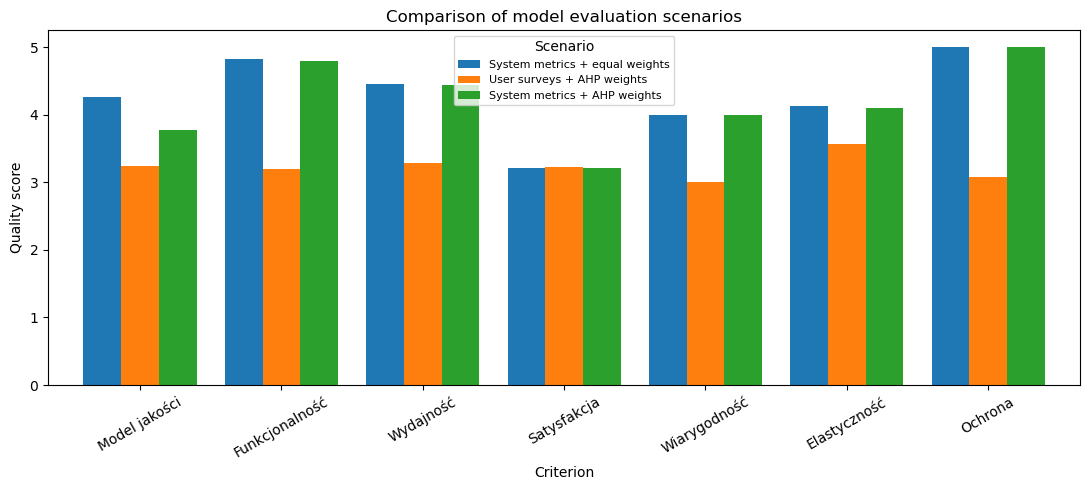

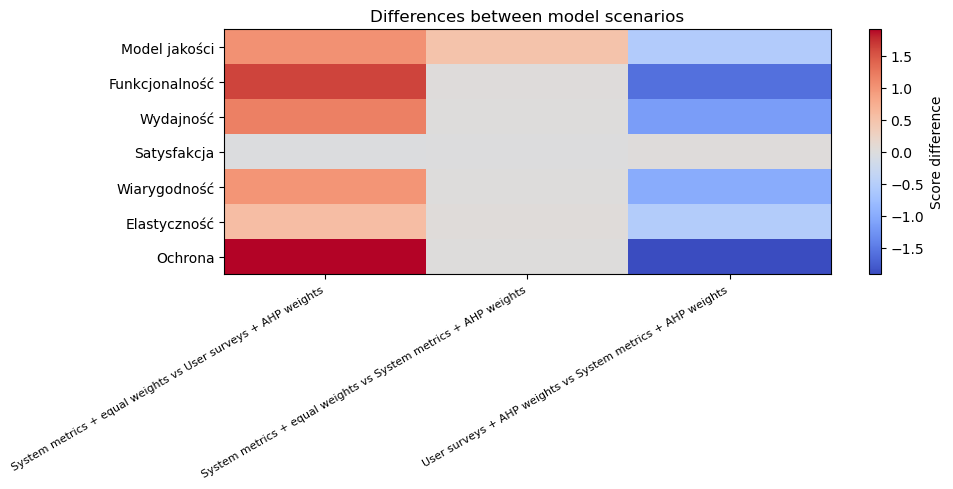

,System metrics + equal weights vs User surveys + AHP weights,System metrics + equal weights vs System metrics + AHP weights,User surveys + AHP weights vs System metrics + AHP weights
Criterion,,,
Model jakości,1.029041,0.489368,-0.539674
Funkcjonalność,1.620022,0.020952,-1.599070
Wydajność,1.168083,0.003900,-1.164183
Satysfakcja,-0.021375,-0.005752,0.015623
Wiarygodność,1.000000,0.000000,-1.000000
Elastyczność,0.560960,0.030122,-0.530839
Ochrona,1.916667,0.000000,-1.916667


In [34]:
viz.generate_model_comparison_visualizations(comparison)